# 37 · 생성 모델을 같은 조건에서 평가하기

**이번 질문:** 샘플이 그럴듯해 보이거나 점수 하나가 작아지면 생성 모델이 좋아졌다고 말할 수 있을까요? 두 봉우리 중 하나만 내거나, 학습 그림을 복사해 내는 모델은 어떤 검사에서 드러날까요?

작은 1차원 Gaussian 혼합 모형을 **직접 학습**하고, 정답 분포를 아는 진단 기준 및 의도적으로 만든 실패 사례와 비교합니다. MNIST에서는 고정 예시를 복제해 특징 통계만으로 놓치는 정보를 확인합니다. 여기의 결과는 이 작은 실험의 진단이며 GAN·VAE·diffusion의 벤치마크 순위가 아닙니다.

- 준비물: [11](../02_연결/11_linear_algebra.ipynb)의 평균·공분산, [12](../02_연결/12_gaussian_information.ipynb)의 Gaussian 로그 밀도, [15](../02_연결/15_experiments_evaluation.ipynb)의 분할·설정 고정·seed 비교, [23](23_latent_mixture_em.ipynb)의 혼합 모형과 EM. 거리의 배열 연산은 [00b](../00_기초/00b_vectorization.ipynb)를 다시 씁니다.
- 도착점: held-out NLL, 영역 질량, RBF MMD², 특징 통계, 최근접 거리, 표본 수와 생성 시간을 각각 계산하고 무엇을 확인했는지 설명합니다.
- 다음 연결: [25 VAE](25_vae.ipynb)의 복원·생성, [28 GAN](28_gan.ipynb)의 mode 누락, [32 score](32_score_matching.ipynb)–[35b EDM](35b_edm.ipynb)의 샘플·비용 비교에 같은 분모와 평가 절차를 적용합니다.

### 읽는 법

| 표시 | 뜻 | 어떻게 읽나 |
|---|---|---|
| 🔑 핵심 | 수식·규칙·구현 | 코드를 가리고 같은 계산을 다시 써 봅니다 |
| 🔍 확인 | 검산·그림 해석 | 실제 출력과 예상이 같은지 확인합니다 |
| 📎 참고 | 환경·용어·연결 | 필요한 자리에서 다시 찾아봅니다 |
| ✏️ 연습 | 핵심 한두 줄·직접 변형 | 손계산 뒤 `run_check`로 확인합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. `-mean(log p_model(test))`와 `-mean(log p_data(generated))`는 평균내는 데이터와 밀도가 다릅니다. 전자는 모델의 관측 설명 능력이고, 후자는 정답 밀도를 아는 모의 실험에서만 가능한 샘플 진단입니다.
2. RBF MMD²는 세 커널 행렬의 평균으로 계산합니다. 여기서는 대각항을 포함한 **biased V통계**를 일관되게 쓰며, 표본 수·전처리·대역폭을 고정합니다.
3. 평균·공분산이나 작은 MMD만으로 새로운 샘플을 배웠다고 단정할 수 없습니다. 고유 표본 수·train/test 최근접 거리와 여러 seed의 결과를 함께 읽습니다.

| 기호 | shape | 의미 |
|---|---|---|
| $X_{tr},X_{te}$ | $(N_{tr},D),(N_{te},D)$ | 학습 관측과 고정 평가 관측 |
| $G$ | $(M,D)$ | 한 후보가 만든 정확히 $M$개 표본 |
| $\mu,s$ | $(D,)$ | 학습 관측만으로 정한 중심과 척도 |
| $K_{XX},K_{GG},K_{XG}$ | $(N,N),(M,M),(N,M)$ | 자기 쌍과 두 집합 사이의 커널 값 |
| $F$ | $(N,d_f)$ | 그림마다 직접 정한 특징 벡터 |

[전체 학습 경로](../../docs/CURRICULUM.md) · [글 규칙](../../docs/WRITING.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/generative_evaluation_plots.py)

In [1]:
# 준비 셀: 실행만 하고 넘어가도 됩니다.
import sys
from pathlib import Path
import time
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/utils/plotting.py").is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.data.mnist import load_mnist, load_examples
from src.utils import setup_plots, run_check
from src.utils.generative_evaluation_plots import (
    plot_evaluation_protocol, plot_density_diagnostics, plot_em_learning, plot_mmd_terms,
    plot_mmd_sensitivity, plot_feature_summary, plot_copy_diagnostics,
    plot_paired_protocol, plot_comparison_summary,
)
setup_plots()
print("NumPy", np.__version__, "· 모든 계산은 CPU, float64입니다.")

NumPy 2.4.6 · 모든 계산은 CPU, float64입니다.


### 📎 이 노트북의 예시와 실험 경계

- **두 봉우리:** 정답은 $p_\star(x)=\frac12\mathcal N(x;-2,0.5^2)+\frac12\mathcal N(x;2,0.5^2)$입니다. 학습 관측 600개, 별도 seed의 평가 관측 512개를 만들고, 각 후보에서 256개씩 생성합니다. 정답 파라미터는 oracle 진단에만 쓰고 EM은 학습 관측만 봅니다.
- **MNIST:** 실제 손글씨의 학습 파일 앞 400장과 별도 test 파일 앞 400장을 사용합니다. `load_examples()`의 고정 0–9 열 장을 20번씩 복제한 200장은 **기억하기만 하는 비교군**입니다. 이미지 생성 모델을 학습했다는 예제가 아닙니다.
- **반복:** 마지막 실험은 고정 train/test에서 학습 초기화·생성 seed를 다섯 번 바꿉니다. 표준편차는 이 조건에서의 실행 변동이고, 데이터셋이나 test 선택의 불확실성까지 나타내지 않습니다.

> **용어**
>
> - **held-out:** 파라미터 학습과 설정 선택에 쓰지 않고 평가용으로 따로 둔 관측입니다.
> - **oracle:** 모의 실험에서만 알고 있는 정답 분포를 이용하는 진단 기준입니다. 학습해 얻은 모델과 구분합니다.
> - **seed:** 난수열을 재현하는 시작 번호입니다. 같은 seed를 여러 번 실행한 것은 새로운 독립 실험이 아닙니다.

## 🔑 1. 점수를 재기 전에 같은 질문과 분모를 정합니다

**이 절에서 가져갈 것:** 관측을 설명하는가, 입력을 복원하는가, 새 표본을 만드는가를 구분하고 비교 조건을 먼저 고정합니다.

한 모델은 그림을 잘 복원하고, 다른 모델은 여러 모양의 새 그림을 만듭니다. 같은 "오차"라는 이름을 붙여도 두 모델이 답한 질문은 다릅니다.

$$\mathrm{NLL}_{test}=-\frac1N\sum_n\log p_\theta(x_n),\qquad
\mathrm{reconstruction}=\frac1{ND}\sum_{n,d}(x_{nd}-\hat x_{nd})^2.$$

NLL은 **모델 밀도**가 새 관측에 주는 값을 평균냅니다. 복원 오차는 입력과 그 입력의 복원 쌍이 있어야 계산할 수 있습니다. 생성 표본만 주는 GAN 같은 모델에 같은 방식의 NLL을 바로 붙일 수는 없습니다. VAE의 ELBO도 정확한 관측 log likelihood와 구분합니다.

비교 전 고정할 것은 데이터 분할, 전처리를 학습한 범위, 각 후보의 생성 개수, 지표 정의, 반복 seed와 시간 측정 범위입니다. 전처리는 15번처럼 학습 자료의 $\mu,s$만 구해 $\tilde x=(x-\mu)/s$를 모든 집합에 적용합니다. 아래에서는 미래 값 100을 평균에 넣지 않는 모습을 봅니다.

In [2]:
protocol_train = np.array([[1., 2.], [3., 4.], [5., 6.]])
protocol_test = np.array([[100., 4.]])
protocol_mean = protocol_train.mean(axis=0)
protocol_scale = protocol_train.std(axis=0)
protocol_transformed = (protocol_test - protocol_mean) / protocol_scale
protocol_counts = np.array([600, 512, 256])

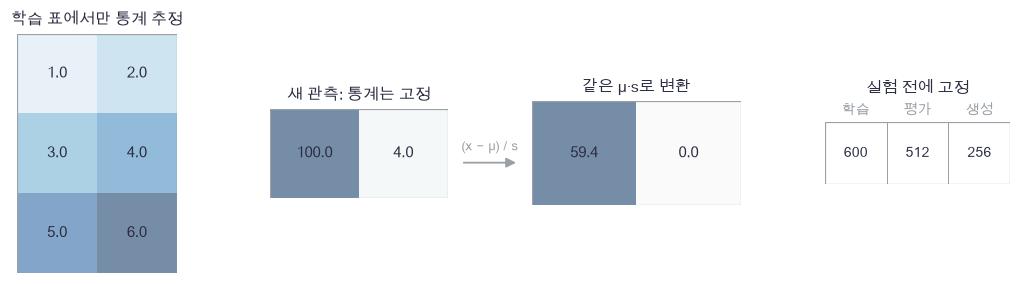

In [3]:
plot_evaluation_protocol(protocol_train, protocol_test, protocol_transformed, protocol_counts)

🔍 **확인** · 학습 표의 평균은 $(3,4)$이고, 새 값 100은 첫 특성에서 약 59.4 표준편차만큼 떨어져 있습니다. 새 값을 섞어 평균을 다시 구하면 평가 기준 자체가 달라집니다. 오른쪽의 600·512·256은 학습·평가·생성 표본 수이며 마지막 비교까지 유지합니다.

In [4]:
def fit_standardizer(X):
    """학습 관측의 μ·s. X: (N, D) → mean, scale: (D,), 상수 열의 척도는 1."""
    mean = X.mean(axis=0)
    scale = X.std(axis=0)
    return mean, np.where(scale > 1e-12, scale, 1.)


def transform(X, mean, scale):
    """고정 μ·s로 좌표 변환. X: (N, D), mean, scale: (D,) → (N, D)."""
    return (X - mean) / scale

In [5]:
PLAN = {
    "train_count": 600, "test_count": 512, "generated_count": 256,
    "train_seed": 3701, "test_seed": 3702, "repeat_seeds": [3711, 3712, 3713, 3714, 3715],
    "components": 2, "em_steps": 40, "variance_floor": 1e-3,
    "bandwidth_train_count": 128, "coverage_threshold": .05,
}
hand_mean, hand_scale = fit_standardizer(protocol_train)
np.testing.assert_allclose(hand_mean, [3., 4.])  # 검산: 열별 손계산 평균
np.testing.assert_allclose(transform(protocol_test, hand_mean, hand_scale), protocol_transformed)  # 검산: 그림과 같은 고정 변환
np.testing.assert_allclose(transform(protocol_train, hand_mean, hand_scale).mean(axis=0), 0.)  # 검산: 학습 열 평균은 0
constant_mean, constant_scale = fit_standardizer(np.array([[1., 4.], [3., 4.]]))
np.testing.assert_allclose(constant_scale, [1., 1.])  # 검산: 상수 열에서 0으로 나누지 않음
print("고정 계획:", PLAN)

고정 계획: {'train_count': 600, 'test_count': 512, 'generated_count': 256, 'train_seed': 3701, 'test_seed': 3702, 'repeat_seeds': [3711, 3712, 3713, 3714, 3715], 'components': 2, 'em_steps': 40, 'variance_floor': 0.001, 'bandwidth_train_count': 128, 'coverage_threshold': 0.05}


### ✏️ 연습 1 · 새 표에도 학습 통계 하나만 쓰기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

새 표 `X:(N,D)`에 학습 평균·척도 `mean, scale:(D,)`를 적용하는 한 줄을 채우세요. 새 표의 평균은 구하지 않습니다.

In [6]:
def exercise_fixed_transform(X, mean, scale):
    """연습 1: 고정 통계로 변환. X: (N, D), mean, scale: (D,) → Z: (N, D)."""
    ### 구현할 내용: Z = (X - mean) / scale
    raise NotImplementedError
    return Z

In [7]:
def check_fixed_transform(candidate):
    """새 표의 크기가 달라도 같은 통계를 쓰는지 손계산합니다."""
    actual = candidate(np.array([[5., 8.], [1., 2.]]), np.array([3., 4.]), np.array([2., 2.]))
    np.testing.assert_allclose(actual, [[1., 2.], [-1., -1.]])  # 검산: 정해 둔 μ·s로 손계산
    one = candidate(np.array([[103., 4.]]), np.array([3., 4.]), np.array([2., 2.]))
    np.testing.assert_allclose(one, [[50., 0.]])  # 검산: 새 표 하나를 자체 중심화하면 안 됨
    print("학습 통계 고정: 손계산과 일치합니다.")

run_check(check_fixed_transform, exercise_fixed_transform, hint="Z = (X - mean) / scale")

☐ exercise_fixed_transform: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: Z = (X - mean) / scale


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
Z = (X - mean) / scale
```

</details>

## 🔑 2. 밀도가 높은 샘플과 모든 봉우리를 만드는 것은 다릅니다

**이 절에서 가져갈 것:** 모델 자신의 held-out NLL, 정답 밀도로 잰 샘플 진단, 영역 질량을 따로 계산합니다.

샘플을 항상 왼쪽 봉우리의 꼭대기 $x=-2$에 놓으면 정답 밀도는 큽니다. 하지만 오른쪽 그림은 한 장도 만들지 못합니다. 따라서 $-\mathbb E_{g\sim p_\theta}\log p_\star(g)$가 작다는 것만으로 생성 분포가 맞다고 할 수 없습니다.

$$p_\theta(x)=\sum_{k=1}^K\pi_k\mathcal N(x;\mu_k,\sigma_k^2),\qquad
\log p_\theta(x)=m+\log\sum_k e^{a_k-m},\quad
a_k=\log\pi_k-\tfrac12[\log(2\pi\sigma_k^2)+(x-\mu_k)^2/\sigma_k^2].$$

$a:(N,K)$는 각 관측·성분의 로그 항이며, 행별 최대 $m$을 빼서 지수의 넘침을 막습니다. 생성에서는 먼저 성분 번호를 $\pi$로 뽑고 해당 Gaussian에서 점을 뽑습니다. 23번의 결합→주변화→샘플링 계산입니다.

이 예제는 $x<0$와 $x\ge0$의 두 영역 비율을 셉니다. 각 영역에 생성 표본의 5% 이상이 있으면 그 영역을 "포함"했다고 정합니다. 이는 사전에 정한 **거친 coverage 진단**이며 성분의 참 잠재 라벨이나 보편적인 생성 품질 지표가 아닙니다. 과하게 넓은 분포도 두 영역을 포함할 수 있습니다.

> **용어** · **mode collapse:** 데이터의 여러 봉우리 중 일부에만 생성 표본이 몰리는 현상입니다. 여기서는 왼쪽 봉우리만 내는 의도적인 비교군으로 관찰합니다.

In [8]:
TRUE_MODEL = {"weights": np.array([.5, .5]), "means": np.array([-2., 2.]), "variances": np.array([.25, .25])}
density_grid = np.linspace(-8., 8., 801)
true_components = np.exp(-.5*((density_grid[:, None]-TRUE_MODEL["means"])**2/.25)) / np.sqrt(2*np.pi*.25)
true_density = (true_components * TRUE_MODEL["weights"]).sum(axis=1)
collapsed_density = np.exp(-.5*(density_grid+2.)**2/.25) / np.sqrt(2*np.pi*.25)
broad_density = np.exp(-.5*density_grid**2/4.25) / np.sqrt(2*np.pi*4.25)
diagnostic_sets = [np.array([-2.4, -1.6, 1.6, 2.4]), np.full(4, -2.), np.array([-5., -1., 1., 5.])]
diagnostic_masses, diagnostic_oracle_scores = [], []
for samples in diagnostic_sets:
    terms = np.exp(-.5*(samples[:, None]-TRUE_MODEL["means"])**2/.25) / np.sqrt(2*np.pi*.25)
    diagnostic_oracle_scores.append(-np.log((terms*.5).sum(axis=1)).mean())
    diagnostic_masses.append([(samples < 0).mean(), (samples >= 0).mean()])
diagnostic_names = ["두 영역 예시", "왼쪽만 예시", "과하게 넓은 예시"]

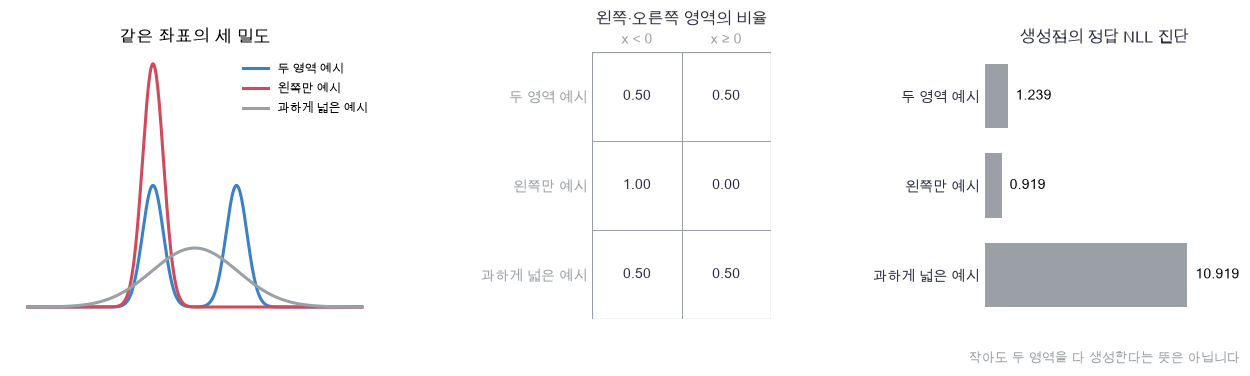

In [9]:
plot_density_diagnostics(density_grid, [true_density, collapsed_density, broad_density], diagnostic_names, diagnostic_masses, diagnostic_oracle_scores)

🔍 **확인** · 가운데 표에서는 왼쪽만 내는 예시의 오른쪽 질량이 0입니다. 반면 너무 넓은 예시는 양쪽을 모두 포함합니다. 오른쪽 정답 NLL 진단은 꼭대기만 복사하는 예시에 유리할 수 있습니다. 이 그림의 4개 점은 수식의 성질을 보이는 손계산 예시이며 학습 모델의 성능 측정값이 아닙니다. 왼쪽 곡선은 참고용 밀도이며, 가운데·오른쪽 수치는 그 곡선에서 적분한 기대값이 아니라 별도로 고른 각 4점에서 계산한 것입니다.

아래에서는 먼저 밀도·생성을 구현하고, 실제 학습 관측 600개로 EM을 돌립니다. EM의 파라미터 갱신은 책임확률 $r_{nk}$로 가중한 평균·분산이며, test 관측은 사용하지 않습니다.

In [10]:
def mixture_logpdf(X, model):
    """1차원 혼합 로그 밀도. X: (N, 1), model의 각 배열: (K,) → (N,)."""
    delta = X[:, 0, None] - model["means"]
    terms = np.log(model["weights"]) - .5*(np.log(2*np.pi*model["variances"]) + delta**2/model["variances"])
    maximum = terms.max(axis=1, keepdims=True)
    return (maximum + np.log(np.exp(terms-maximum).sum(axis=1, keepdims=True)))[:, 0]


def sample_mixture(model, count, rng):
    """성분을 먼저 뽑고 Gaussian 샘플 생성. model: K개 성분, count: 정수 → (count, 1)."""
    component = rng.choice(len(model["weights"]), size=count, p=model["weights"])
    samples = model["means"][component] + np.sqrt(model["variances"][component])*rng.normal(size=count)
    return samples[:, None]

In [11]:
def fit_gmm(X, rng, steps=40, variance_floor=1e-3):
    """EM으로 1차원 2성분 GMM 학습. X: (N, 1) → (최종 model, 평균 log likelihood 기록, 초기 model)."""
    # 1. 학습 자료의 분위수로 두 평균을 시작하고 작은 초기화 잡음을 더합니다.
    values = X[:, 0]
    weights = np.full(2, .5)
    means = np.quantile(values, [.25, .75]) + rng.normal(scale=.1, size=2)
    variances = np.full(2, values.var())
    initial = {"weights": weights.copy(), "means": means.copy(), "variances": variances.copy()}
    history = []
    # 2. E 단계: 안정적인 softmax로 각 관측의 책임확률을 계산합니다.
    for step in range(steps):
        terms = np.log(weights) - .5*(np.log(2*np.pi*variances)+(values[:, None]-means)**2/variances)
        maximum = terms.max(axis=1, keepdims=True)
        exp_terms = np.exp(terms-maximum)
        normalizer = exp_terms.sum(axis=1, keepdims=True)
        responsibilities = exp_terms / normalizer
        history.append(float((maximum+np.log(normalizer)).mean()))
        # 3. M 단계: 책임확률로 가중한 비율·평균·분산입니다.
        counts = responsibilities.sum(axis=0)
        weights = counts / len(values)
        means = (responsibilities*values[:, None]).sum(axis=0) / counts
        variances = (responsibilities*(values[:, None]-means)**2).sum(axis=0) / counts
        variances = np.maximum(variances, variance_floor)
    # 4. 마지막 갱신까지 목적을 기록하고 성분 순서만 왼쪽부터 정렬합니다.
    order = np.argsort(means)
    model = {"weights": weights[order], "means": means[order], "variances": variances[order]}
    history.append(float(mixture_logpdf(X, model).mean()))
    return model, np.asarray(history), initial

In [12]:
def region_mass(X):
    """왼쪽·오른쪽 영역의 표본 비율. X: (N, 1) → (2,), 잠재 성분 라벨 추정이 아닙니다."""
    return np.array([(X[:, 0] < 0).mean(), (X[:, 0] >= 0).mean()])


def heldout_nll(X, model):
    """모델 자신의 밀도로 새 관측을 평가. X: (N, 1), model: 혼합 모형 → 평균 NLL 숫자."""
    return float(-mixture_logpdf(X, model).mean())

In [13]:
# 쓰는 것: PLAN (1절) · TRUE_MODEL (2절) · density_grid (2절)
train_X = sample_mixture(TRUE_MODEL, PLAN["train_count"], np.random.default_rng(PLAN["train_seed"]))
test_X = sample_mixture(TRUE_MODEL, PLAN["test_count"], np.random.default_rng(PLAN["test_seed"]))
fitted_model, em_history, initial_model = fit_gmm(train_X, np.random.default_rng(3703), PLAN["em_steps"], PLAN["variance_floor"])
fitted_density = np.exp(mixture_logpdf(density_grid[:, None], fitted_model))
initial_density = np.exp(mixture_logpdf(density_grid[:, None], initial_model))
print("학습 결과:", fitted_model)
print("모델 자신의 held-out NLL:", heldout_nll(test_X, fitted_model))

학습 결과: {'weights': array([0.50166532, 0.49833468]), 'means': array([-1.98550639,  2.00829371]), 'variances': array([0.25074411, 0.25963474])}
모델 자신의 held-out NLL: 1.4513004723830252


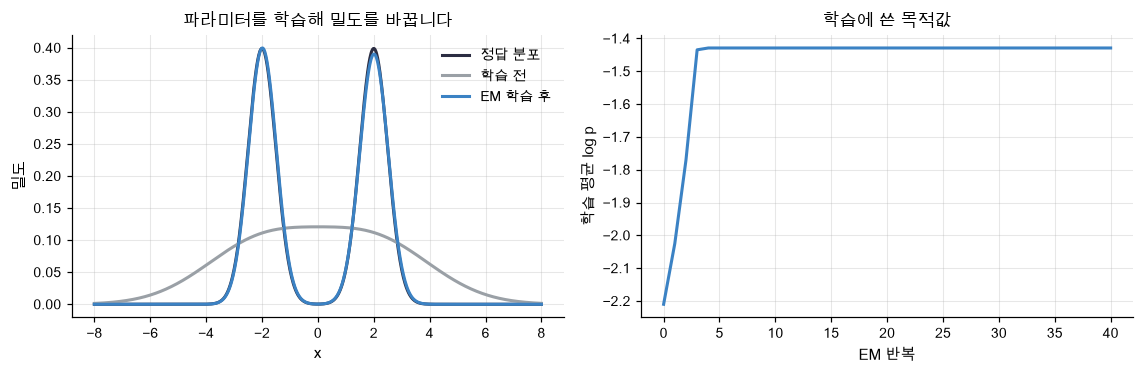

In [14]:
plot_em_learning(density_grid, initial_density, fitted_density, true_density, em_history)

🔍 **확인** · 학습 후 평균은 두 봉우리 근처로 이동하고 분산도 좁아집니다. 오른쪽은 train에서만 계산한 목적이며, 출력한 held-out NLL은 다른 seed로 만든 관측에 **학습한 모델 밀도**를 대입한 것입니다. 정답 분포를 알고 있다는 이유로 학습 결과를 그 값으로 바꾸지 않습니다.

In [15]:
# 쓰는 것: PLAN (1절) · TRUE_MODEL (2절) · mixture_logpdf (2절) · sample_mixture (2절)
single_model = {"weights": np.array([1.]), "means": np.array([2.]), "variances": np.array([4.])}
np.testing.assert_allclose(mixture_logpdf(np.array([[2.]]), single_model), [-.5*np.log(8*np.pi)])  # 검산: 평균에서 거리 항 0
swapped = {key: value[::-1] for key, value in TRUE_MODEL.items()}
np.testing.assert_allclose(mixture_logpdf(test_X[:8], swapped), mixture_logpdf(test_X[:8], TRUE_MODEL))  # 검산: 성분 이름을 바꿔도 주변 밀도 동일
assert np.all(np.diff(em_history) >= -1e-9), "이 예제의 EM 학습 우도는 감소하지 않아야 합니다"
assert np.all(fitted_model["variances"] > PLAN["variance_floor"]), "이 검산에서는 분산 바닥값이 활성화되지 않아야 합니다"
np.testing.assert_allclose(region_mass(np.array([[-2.], [0.], [2.]])), [1/3, 2/3])  # 검산: 경계 0은 오른쪽 영역
sample_check = sample_mixture(TRUE_MODEL, 20000, np.random.default_rng(3704))
np.testing.assert_allclose(sample_check.mean(), 0., atol=.06)  # 검산: 대칭 혼합의 기댓값 0에 가까움
np.testing.assert_allclose(sample_check.var(), 4.25, atol=.12)  # 검산: 성분 내 분산 .25 + 성분 간 분산 4
print("밀도 손계산·성분 순서·EM 목적·생성 모멘트 검산 통과")

밀도 손계산·성분 순서·EM 목적·생성 모멘트 검산 통과


### ✏️ 연습 2 · 생성 개수가 바뀌어도 영역의 비율을 세기

음수 영역에 놓인 개수를 전체 생성 수로 나눠 `left_mass`를 만들고, 나머지를 `right_mass`로 반환하세요. 0은 오른쪽에 포함합니다.

In [16]:
def exercise_region_mass(X):
    """연습 2: 영역 질량. X: (N, 1) → masses: (2,)."""
    ### 구현할 내용: 왼쪽 비율을 구하고 나머지 비율과 묶습니다.
    raise NotImplementedError
    return masses

In [17]:
def check_region_mass(candidate):
    """전체·한쪽·경계 관측의 비율을 손으로 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([[-3.], [-1.], [0.], [2.]])), [.5, .5])  # 검산: 음수 두 개 / 네 개
    np.testing.assert_allclose(candidate(np.array([[-2.], [-1.], [-3.]])), [1., 0.])  # 검산: 한 영역 누락
    np.testing.assert_allclose(candidate(np.array([[0.]])), [0., 1.])  # 검산: 경계는 오른쪽
    print("영역 질량: 손계산과 일치합니다.")

run_check(check_region_mass, exercise_region_mass, hint="left_mass = (X[:, 0] < 0).mean(), masses = np.array([left_mass, 1-left_mass])")

☐ exercise_region_mass: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: left_mass = (X[:, 0] < 0).mean(), masses = np.array([left_mass, 1-left_mass])


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
left_mass = (X[:, 0] < 0).mean()
masses = np.array([left_mass, 1-left_mass])
```

</details>

## 🔑 3. RBF MMD²를 커널 행렬 세 개로 계산합니다

**이 절에서 가져갈 것:** 대각항을 포함한 V통계의 분모·전처리·대역폭을 고정하고 손계산→반복문→벡터화로 대조합니다.

두 영역의 표본 비율만 같아도 봉우리 폭은 전혀 다를 수 있습니다. 가까운 두 점에는 큰 값, 먼 두 점에는 작은 값을 주어 두 표본 묶음의 관계를 비교하겠습니다.

$$k_h(x,y)=\exp\left(-\frac{\|x-y\|^2}{2h^2}\right),\qquad
\widehat{\mathrm{MMD}}^2_V=\frac1{N^2}\sum_{i,j}k_h(x_i,x_j)+\frac1{M^2}\sum_{i,j}k_h(g_i,g_j)-\frac2{NM}\sum_{i,j}k_h(x_i,g_j).$$

같은 집합 안의 닮음 두 항에서 집합 사이 닮음의 두 배를 뺍니다. **$i=j$인 자기 쌍을 포함**하고 $N^2,M^2,NM$으로 나눕니다. 이 노트북의 `mmd2_v`는 제곱근을 취하지 않은 이 수식 그대로입니다.

> **용어**
>
> - **커널(kernel):** 두 점의 닮음을 재는 함수입니다. 여기서는 거리의 제곱에 따라 줄어드는 Gaussian RBF를 씁니다.
> - **대역폭 $h$:** 어느 거리까지 가깝다고 볼지 정하는 척도입니다. 크면 먼 점도 닮았다고 봅니다.
> - **MMD:** 선택한 커널로 두 분포의 차이를 재는 값입니다. 여기서는 유한 표본에서 계산한 제곱 값을 씁니다.
> - **biased V통계:** 자기 쌍까지 포함한 표본 계산입니다. 모집단 MMD²의 불편 추정량이 아니므로 작은 표본에서의 값을 직접 같은 척도로 비교하지 않습니다.

$X=(0,1)$, $G=(0,2)$, $h=1$이면 $a=e^{-1/2}$를 써서 결과가 $(1-a)/2$입니다. 아래 세 표의 모든 칸을 더해 각 칸 수로 나누어 확인해 보세요.

In [18]:
mmd_hand_X, mmd_hand_G = np.array([[0.], [1.]]), np.array([[0.], [2.]])
hand_kxx = np.exp(-.5*(mmd_hand_X-mmd_hand_X.T)**2)
hand_kgg = np.exp(-.5*(mmd_hand_G-mmd_hand_G.T)**2)
hand_kxg = np.exp(-.5*(mmd_hand_X-mmd_hand_G.T)**2)
hand_terms = [hand_kxx.mean(), hand_kgg.mean(), -2*hand_kxg.mean()]
hand_terms.append(sum(hand_terms))

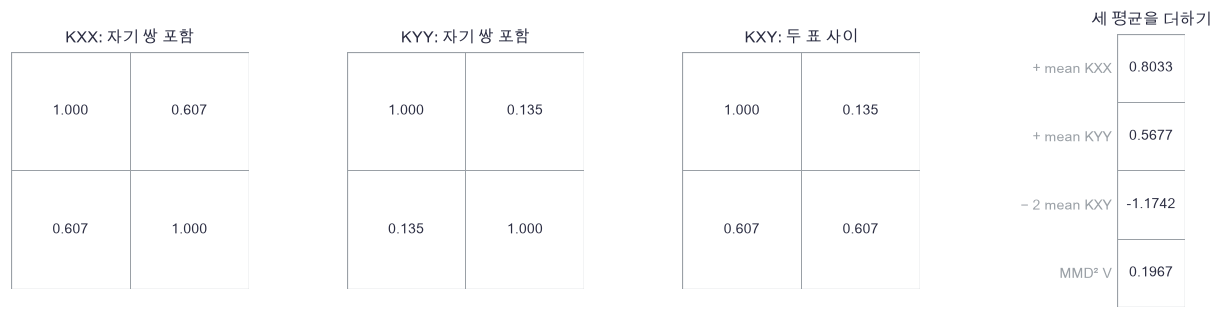

In [19]:
plot_mmd_terms(hand_kxx, hand_kgg, hand_kxg, hand_terms)

🔍 **확인** · 자기 쌍의 대각 칸은 모두 1입니다. 행렬 세 개의 평균을 조합하면 약 0.1967이며, 두 표본의 크기가 다를 때에도 각 행렬의 실제 칸 수가 분모입니다. 원전의 biased MMD 식 (5)를 제곱한 형태를 사용합니다. [Gretton 외, JMLR 2012](https://www.jmlr.org/papers/volume13/gretton12a/gretton12a.pdf).

In [20]:
def squared_distances(X, Y):
    """모든 쌍의 제곱 거리. X: (N, D), Y: (M, D) → (N, M). 큰 (N,M,D) 임시 배열을 피합니다."""
    distance = (X**2).sum(axis=1)[:, None] + (Y**2).sum(axis=1)[None, :] - 2*X @ Y.T
    return np.maximum(distance, 0.)


def rbf_kernel(X, Y, bandwidth):
    """k_h(x,y)=exp(-거리²/(2h²)). X: (N,D), Y: (M,D), bandwidth>0 → (N,M)."""
    if bandwidth <= 0:
        raise ValueError("대역폭은 양수여야 합니다.")
    return np.exp(-squared_distances(X, Y)/(2*bandwidth**2))


def mmd2_v(X, Y, bandwidth):
    """대각항을 포함한 biased MMD² V통계. X: (N,D), Y: (M,D) → 숫자, 반올림 수준 음수는 그대로 둡니다."""
    return float(rbf_kernel(X, X, bandwidth).mean()+rbf_kernel(Y, Y, bandwidth).mean()-2*rbf_kernel(X, Y, bandwidth).mean())

In [21]:
def mean_kernel_loops(X, Y, bandwidth):
    """반복문으로 모든 쌍 커널의 평균을 계산합니다. X: (N,D), Y: (M,D) → 숫자."""
    total = 0.
    for x in X:
        for y in Y:
            total += np.exp(-np.sum((x-y)**2)/(2*bandwidth**2))
    return total / (len(X)*len(Y))


def mmd2_v_loops(X, Y, bandwidth):
    """검산용 반복문 MMD². 자기 쌍을 빼지 않고 각 집합 크기로 나눕니다."""
    return mean_kernel_loops(X, X, bandwidth)+mean_kernel_loops(Y, Y, bandwidth)-2*mean_kernel_loops(X, Y, bandwidth)

In [22]:
# 쓰는 것: hand_terms (3절) · mmd_hand_G (3절) · mmd_hand_X (3절)
np.testing.assert_allclose(mmd2_v(mmd_hand_X, mmd_hand_G, 1.), (1-np.exp(-.5))/2)  # 검산: 손계산 .1967...
np.testing.assert_allclose(mmd2_v_loops(mmd_hand_X, mmd_hand_G, 1.), hand_terms[-1])  # 검산: 그림의 세 평균
distance_hand = squared_distances(np.array([[0., 0.], [1., 2.]]), np.array([[1., 0.], [0., 2.]]))
np.testing.assert_allclose(distance_hand, [[1., 4.], [4., 1.]])  # 검산: 두 좌표에서 손으로 잰 거리²
unequal_X, unequal_G = np.array([[0., 1.], [2., 3.], [-1., 2.]]), np.array([[1., 0.], [2., 2.]])
np.testing.assert_allclose(mmd2_v(unequal_X, unequal_G, .7), mmd2_v_loops(unequal_X, unequal_G, .7))  # 검산: N=3, M=2의 실제 분모
np.testing.assert_allclose(mmd2_v(unequal_X, unequal_X, .7), 0., atol=1e-12)  # 검산: 같은 경험 분포는 0
np.testing.assert_allclose(mmd2_v(unequal_X, unequal_G, .7), mmd2_v(unequal_G, unequal_X, .7))  # 검산: 집합 교환 대칭
np.testing.assert_allclose(mmd2_v(unequal_X, np.repeat(unequal_X, 2, axis=0), .7), 0., atol=1e-12)  # 검산: 똑같이 복제한 경험 분포도 0
assert mmd2_v(unequal_X, unequal_G, .7) >= -1e-12, "RBF의 V통계 제곱은 반올림 오차 밖에서 음수가 아니어야 합니다"
print("MMD²: 손계산·반복문·벡터화·대칭·동일/복제 표본 검산 통과")

MMD²: 손계산·반복문·벡터화·대칭·동일/복제 표본 검산 통과


📎 **평가 커널을 고정하기** · 1절의 학습 계획대로 train에서 중심·척도를 구하고, 앞 128개 학습 관측 쌍의 **양수 거리 중앙값**을 $h$로 정합니다. test나 생성 결과를 보고 $h$를 고르지 않습니다. 아래 대역폭 변화 그림은 민감도를 설명하는 별도 진단이며 최종 표의 $h$를 바꾸지 않습니다.

> **코드** · `np.triu_indices(n, k=1)`은 정사각 표에서 대각 위의 서로 다른 쌍만 고릅니다. 같은 쌍을 두 번 세지 않고 자기 거리 0을 빼려는 용도입니다.

In [23]:
# 쓰는 것: PLAN (1절) · fit_standardizer (1절) · test_X (2절) · train_X (2절) · transform (1절)
train_mean, train_scale = fit_standardizer(train_X)
scaled_train = transform(train_X, train_mean, train_scale)
scaled_test = transform(test_X, train_mean, train_scale)
bandwidth_pool = scaled_train[:PLAN["bandwidth_train_count"]]
pool_distances = squared_distances(bandwidth_pool, bandwidth_pool)
upper_distances = pool_distances[np.triu_indices(len(bandwidth_pool), k=1)]
bandwidth = float(np.sqrt(np.median(upper_distances[upper_distances > 0])))
assert bandwidth > 0, "고정한 RBF 대역폭은 양수여야 합니다"
print("train에서 정한 μ, s, h:", train_mean, train_scale, bandwidth)

train에서 정한 μ, s, h: [0.00474269] [2.0597913] 1.049810989631985


In [24]:
# 쓰는 것: TRUE_MODEL (2절) · mmd2_v (3절) · sample_mixture (2절) · transform (1절)
sensitivity_reference = sample_mixture(TRUE_MODEL, 128, np.random.default_rng(3720))
sensitivity_good = sample_mixture(TRUE_MODEL, 128, np.random.default_rng(3721))
sensitivity_collapsed = np.random.default_rng(3722).normal(-2., .5, size=(128, 1))
sensitivity_h = np.array([.03, .1, .3, 1., 3., 10., 100.])
sensitivity_scores = []
for generated in [sensitivity_good, sensitivity_collapsed]:
    sensitivity_scores.append([mmd2_v(transform(sensitivity_reference, train_mean, train_scale), transform(generated, train_mean, train_scale), h) for h in sensitivity_h])
sample_sizes = np.array([16, 64, 256])
same_distribution_scores = np.empty((3, 8))
for i, size in enumerate(sample_sizes):
    for j in range(8):
        first = sample_mixture(TRUE_MODEL, size, np.random.default_rng(3800+20*i+2*j))
        second = sample_mixture(TRUE_MODEL, size, np.random.default_rng(3801+20*i+2*j))
        same_distribution_scores[i, j] = mmd2_v(transform(first, train_mean, train_scale), transform(second, train_mean, train_scale), bandwidth)
size_means = same_distribution_scores.mean(axis=1)
size_stds = same_distribution_scores.std(axis=1, ddof=1)

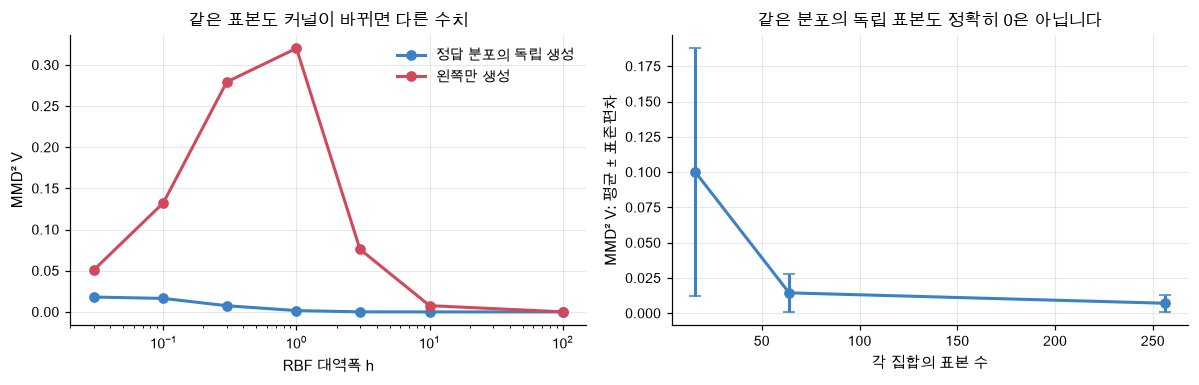

In [25]:
plot_mmd_sensitivity(sensitivity_h, sensitivity_scores, ["정답 분포의 독립 생성", "왼쪽만 생성"], sample_sizes, size_means, size_stds)

🔍 **확인** · $h$가 너무 크면 거의 모든 커널이 1이 되어 다른 분포도 수치가 작아집니다. 매우 작으면 서로 다른 점들의 닮음이 거의 0이고 자기 쌍의 영향이 두드러집니다. 오른쪽은 같은 분포에서 **독립적으로** 뽑은 두 묶음의 값입니다. 평균이 양수일 수 있고 작은 표본에서는 변동도 큽니다. 오차 막대는 8회 실행의 표준편차이며 신뢰구간이 아닙니다.

`MMD²(X,X)=0`은 구현 검산일 뿐 새로운 독립 표본의 성능을 뜻하지 않습니다. 똑같은 표본을 반복해 크기를 늘리면 경험 분포는 그대로라 V통계도 그대로입니다. 따라서 0이라는 숫자로 다양성이나 일반화를 증명할 수 없습니다.

### ✏️ 연습 3 · 거리 표를 RBF 닮음 표로 바꾸기

거리의 제곱 `distance_squared:(N,M)`를 받아 $\exp(-d^2/(2h^2))$를 계산하세요. 입력은 이미 제곱한 거리입니다.

In [26]:
def exercise_rbf_values(distance_squared, bandwidth):
    """연습 3: 거리²에서 RBF. distance_squared: (N,M), bandwidth>0 → kernel: (N,M)."""
    ### 구현할 내용: exp(-거리² / (2*대역폭²))
    raise NotImplementedError
    return kernel

In [27]:
def check_rbf_values(candidate):
    """거리 0·1·4와 대역폭 두 배의 손계산을 검사합니다."""
    d2 = np.array([[0., 1., 4.]])
    np.testing.assert_allclose(candidate(d2, 1.), [[1., np.exp(-.5), np.exp(-2.)]])  # 검산: 이미 제곱된 거리를 한 번만 사용
    np.testing.assert_allclose(candidate(d2, 2.), [[1., np.exp(-.125), np.exp(-.5)]])  # 검산: h²=4로 분모가 바뀜
    print("RBF 닮음: 손계산과 일치합니다.")

run_check(check_rbf_values, exercise_rbf_values, hint="kernel = np.exp(-distance_squared / (2*bandwidth**2))")

☐ exercise_rbf_values: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: kernel = np.exp(-distance_squared / (2*bandwidth**2))


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
kernel = np.exp(-distance_squared / (2*bandwidth**2))
```

</details>

## 🔑 4. 특징 통계가 같아도 학습 그림을 복제했을 수 있습니다

**이 절에서 가져갈 것:** 특징 평균·공분산과 고유 그림 수·train/test 최근접 거리는 서로 다른 정보를 봅니다.

고정 MNIST 열 장을 각각 20번 복사하면 200장이 됩니다. 각 그림의 비중은 여전히 1/10이므로 특징 평균·공분산은 열 장일 때와 같습니다. 그런데 새 그림은 하나도 없습니다.

이 절의 특징 $f(x)$는 전체 잉크 평균, 왼쪽−오른쪽 잉크 평균, 위쪽−아래쪽 잉크 평균 세 개입니다. 모델을 학습한 특징 추출기가 아니며 숫자 모양의 모든 의미를 담지도 않습니다.

$$\mu_F=\frac1N\sum_n f(x_n),\qquad C_F=\frac1N(F-\mu_F)^\top(F-\mu_F),\qquad
d(x,S)=\min_{s\in S}\sqrt{\frac1{784}\sum_d(x_d-s_d)^2}.$$

공분산의 분모는 **$N$**입니다. 그래야 모든 관측을 같은 횟수로 복제했을 때 경험 분포의 통계가 정확히 유지됩니다. 최근접 RMS 거리는 원래 `[0,1]` 화소에서 재며 train과 test의 참조 풀 크기를 각각 400장으로 맞춥니다. 참조 풀 크기가 다르면 최근접 거리는 그 영향도 받습니다.

> **용어**
>
> - **특징(feature):** 비교할 성질을 숫자로 옮긴 값입니다. 특징에 넣지 않은 차이는 이 비교가 놓칠 수 있습니다.
> - **최근접 거리:** 주어진 참조 집합에서 가장 닮은 한 표본까지의 거리입니다. 여기서는 화소 차이의 제곱 평균에 제곱근을 취합니다.
> - **memorization:** 학습 표본을 기억해 다시 내는 것입니다. train 최근접거리 0은 정확한 복제의 단서지만, 비슷하다는 이유만으로 일반적인 암기를 확정하지는 않습니다.

아래의 직접 정한 특징 통계는 **표준 FID가 아닙니다**. 이 세 특징의 숫자가 작다는 사실을 이미지 생성 성능 전체로 읽지 않습니다.

In [28]:
raw_train_images, raw_train_labels, raw_test_images, raw_test_labels = load_mnist(download=True, normalize=False)
mnist_train = raw_train_images[:400].reshape(-1, 28, 28).astype(float) / 255.
mnist_test = raw_test_images[:400].reshape(-1, 28, 28).astype(float) / 255.
del raw_train_images, raw_test_images
mnist_examples, mnist_example_labels = load_examples(download=True)
feature_names = ["잉크 평균", "좌우 차", "상하 차"]
example_7 = mnist_examples[7]
example_features = np.array([example_7.mean(), example_7[:, :14].mean()-example_7[:, 14:].mean(), example_7[:14].mean()-example_7[14:].mean()])
feature_train_before = np.stack([mnist_train.mean(axis=(1, 2)), mnist_train[:, :, :14].mean(axis=(1, 2))-mnist_train[:, :, 14:].mean(axis=(1, 2)), mnist_train[:, :14].mean(axis=(1, 2))-mnist_train[:, 14:].mean(axis=(1, 2))], axis=1)
feature_centered_before = feature_train_before - feature_train_before.mean(axis=0)
feature_cov_before = feature_centered_before.T @ feature_centered_before / len(feature_centered_before)

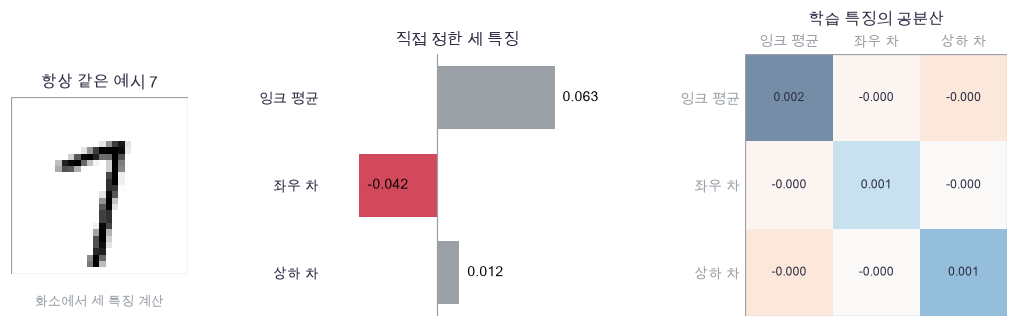

In [29]:
plot_feature_summary(example_7, example_features, feature_cov_before, feature_names)

🔍 **확인** · 같은 7이 세 숫자로 줄었습니다. 왼쪽에 잉크가 더 많으면 좌우 차가 양수입니다. 공분산은 학습 그림 400장의 특징이 함께 변하는 정도입니다. 서로 다른 그림도 이 세 숫자가 같을 수 있고, 같은 그림을 여러 번 복제해도 평균은 바뀌지 않습니다.

In [30]:
# 쓰는 것: squared_distances (3절)
def image_features(images):
    """손으로 정한 세 화소 특징. images: (N,28,28) → (N,3), 순서: 잉크 평균·좌우 차·상하 차."""
    ink = images.mean(axis=(1, 2))
    left_right = images[:, :, :14].mean(axis=(1, 2)) - images[:, :, 14:].mean(axis=(1, 2))
    top_bottom = images[:, :14].mean(axis=(1, 2)) - images[:, 14:].mean(axis=(1, 2))
    return np.stack([ink, left_right, top_bottom], axis=1)


def feature_moments(features):
    """경험 특징 평균·공분산(분모 N). features: (N,d_f) → (mean: (d_f,), covariance: (d_f,d_f))."""
    mean = features.mean(axis=0)
    centered = features - mean
    return mean, centered.T @ centered / len(features)


def nearest_rms(X, reference):
    """같은 화소 좌표의 최근접 RMS 거리. X: (N,D), reference: (R,D) → (distance: (N,), index: (N,))."""
    distances = squared_distances(X, reference)
    index = distances.argmin(axis=1)
    minimum = distances[np.arange(len(X)), index]
    return np.sqrt(minimum / X.shape[1]), index

In [31]:
# 쓰는 것: fit_standardizer (1절)
memorized_images = np.repeat(mnist_examples, 20, axis=0)
original_features = image_features(mnist_examples)
repeated_features = image_features(memorized_images)
original_mean, original_cov = feature_moments(original_features)
repeated_mean, repeated_cov = feature_moments(repeated_features)
feature_train = image_features(mnist_train)
feature_test = image_features(mnist_test)
feature_mu, feature_scale = fit_standardizer(feature_train)
feature_mean_test, feature_cov_test = feature_moments(feature_test)
feature_mean_gap = np.sum((repeated_mean-feature_mean_test)**2)
feature_cov_gap = np.sum((repeated_cov-feature_cov_test)**2)
pixel_train, pixel_test = mnist_train.reshape(400, -1), mnist_test.reshape(400, -1)
pixel_generated = memorized_images.reshape(200, -1)
train_distances, nearest_train_indices = nearest_rms(pixel_generated, pixel_train)
test_distances, nearest_test_indices = nearest_rms(pixel_generated, pixel_test)
unique_fraction = len(np.unique(pixel_generated, axis=0)) / len(pixel_generated)
copy_summary = np.array([unique_fraction, train_distances.mean(), test_distances.mean()])
print("복제 진단: 200장 중 고유 그림", len(np.unique(pixel_generated, axis=0)))
print("직접 정한 특징의 평균 차이² / 공분산 차이²:", feature_mean_gap, feature_cov_gap)

복제 진단: 200장 중 고유 그림 10
직접 정한 특징의 평균 차이² / 공분산 차이²: 7.06040825920751e-05 5.408952927221686e-07


In [32]:
# 쓰는 것: mnist_test (4절) · mnist_train (4절)
copy_display_index = 7*20
copy_display_train = mnist_train[nearest_train_indices[copy_display_index]]
copy_display_test = mnist_test[nearest_test_indices[copy_display_index]]
copy_display_distances = np.array([train_distances[copy_display_index], test_distances[copy_display_index]])

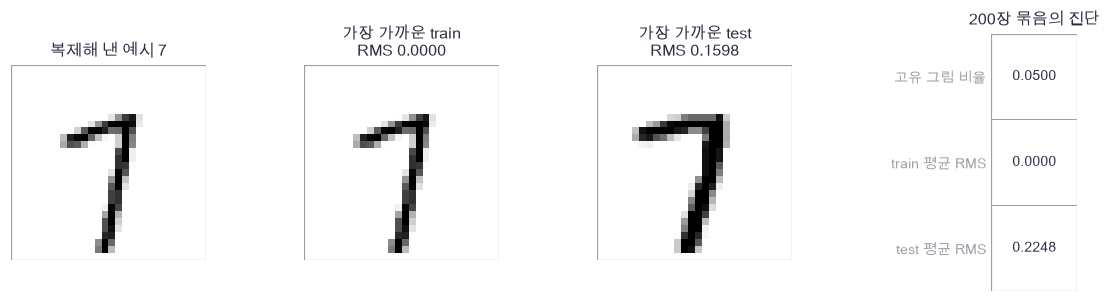

In [33]:
plot_copy_diagnostics(memorized_images[copy_display_index], copy_display_train, copy_display_test, copy_display_distances, copy_summary)

🔍 **확인** · 생성했다고 부른 200장은 실제로 고정 열 장의 복사본이며 고유 그림 비율은 0.05입니다. train에는 원본이 있으므로 화소 RMS 거리가 반올림 오차 안에서 0이고, 별도 test 풀에서는 같은 원본을 찾지 못합니다. 이 예제는 복제를 우리가 직접 만들었으므로 원인을 알고 있습니다. 실제 생성 모델에서는 작은 거리만 보고 단정하지 않고 최근접 그림과 데이터 중복도 확인해야 합니다.

test와 비교한 특징 차이 두 개는 이 세 특징에서의 차이만 말합니다. 아래에서 원본 열 장과 200장 복제 묶음의 평균·공분산·MMD²가 같다는 것을 검산합니다.

In [34]:
# 쓰는 것: example_features (4절) · feature_cov_before (4절) · feature_moments (4절) · feature_train_before (4절) · image_features (4절) · mmd2_v (3절) · mnist_examples (4절) · nearest_rms (4절) · transform (1절)
np.testing.assert_allclose(image_features(mnist_examples)[7], example_features)  # 검산: 개념 그림의 직접 계산과 같음
np.testing.assert_allclose(feature_train, feature_train_before)  # 검산: 전체 학습 특징도 본문 그림 계산과 같음
np.testing.assert_allclose(feature_moments(feature_train)[1], feature_cov_before)  # 검산: 공분산의 분모 N 일치
np.testing.assert_allclose(repeated_mean, original_mean, atol=1e-14)  # 검산: 균등 복제하면 평균 불변
np.testing.assert_allclose(repeated_cov, original_cov, atol=1e-14)  # 검산: 분모 N의 공분산도 불변
feature_original_scaled = transform(original_features, feature_mu, feature_scale)
feature_repeated_scaled = transform(repeated_features, feature_mu, feature_scale)
np.testing.assert_allclose(mmd2_v(feature_original_scaled, feature_repeated_scaled, 1.), 0., atol=1e-12)  # 검산: 같은 경험 분포의 MMD² V도 0
np.testing.assert_allclose(unique_fraction, .05)  # 검산: 고유 10장 / 200장
assert train_distances.max() < 1e-7, "원본이 train에 있으므로 RMS 거리는 반올림 오차 안에서 0이어야 합니다"
tiny_distance, tiny_index = nearest_rms(np.array([[0., 0.], [2., 0.]]), np.array([[0., 0.], [0., 2.]]))
np.testing.assert_allclose(tiny_distance, [0., np.sqrt(2.)])  # 검산: 제곱 거리 0·4를 D=2로 나눈 뒤 제곱근
np.testing.assert_array_equal(tiny_index, [0, 0])  # 검산: 동률이면 첫 참조 표본
print("특징 통계·균등 복제·최근접 거리 검산 통과")

특징 통계·균등 복제·최근접 거리 검산 통과


### ✏️ 연습 4 · 200장 안에 서로 다른 그림은 몇 장일까요?

그림을 펼친 `flat:(N,D)`는 미리 준비했습니다. 서로 다른 행의 수를 전체 행 수로 나눠 고유 그림 비율을 구하세요. `np.unique(flat, axis=0)`은 중복 행을 한 번씩만 남깁니다.

In [35]:
def exercise_unique_fraction(images):
    """연습 4: 고유 그림 비율. images: (N,...) → fraction: 0보다 크고 1 이하인 숫자."""
    flat = images.reshape(len(images), -1)
    ### 구현할 내용: 서로 다른 행 수 / 전체 행 수
    raise NotImplementedError
    return fraction

In [36]:
def check_unique_fraction(candidate):
    """똑같은 그림 셋과 다른 그림 하나, 전부 다른 경우를 셉니다."""
    images = np.array([[[1., 0.]], [[1., 0.]], [[0., 1.]], [[1., 0.]]])
    np.testing.assert_allclose(candidate(images), .5)  # 검산: 서로 다른 그림 2개 / 총 4개
    np.testing.assert_allclose(candidate(np.zeros((4, 2, 2))), .25)  # 검산: 모두 같으면 1/4
    np.testing.assert_allclose(candidate(np.arange(6.).reshape(3, 1, 2)), 1.)  # 검산: 모두 다르면 3/3
    print("고유 그림 비율: 손계산과 일치합니다.")

run_check(check_unique_fraction, exercise_unique_fraction, hint="fraction = len(np.unique(flat, axis=0)) / len(flat)")

☐ exercise_unique_fraction: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: fraction = len(np.unique(flat, axis=0)) / len(flat)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
fraction = len(np.unique(flat, axis=0)) / len(flat)
```

</details>

## 🔑 5. 고정 계획으로 학습·생성·평가를 끝까지 연결합니다

**이 절에서 가져갈 것:** 같은 train/test·생성 수·지표를 사용하고 seed를 실험 단위로 기록하며, 생성 시간의 범위를 명시합니다.

한 번 운 좋게 뽑은 표본 묶음이 후보의 순위를 바꿀 수 있습니다. 마지막 실험은 1절에서 정한 seed 다섯 개를 모두 사용하고 누락하거나 좋은 실행만 고르지 않습니다. 각 행은 **GMM 초기화와 생성 난수를 바꾼 한 실행**입니다.

$$\bar q=\frac1R\sum_{r=1}^R q_r,\qquad s_q=\sqrt{\frac1{R-1}\sum_r(q_r-\bar q)^2},\qquad d_r=q_{B,r}-q_{A,r}.$$

평균과 표준편차를 함께 보고, 같은 실행 행끼리 차이 $d_r$도 봅니다. 반복 사이 train/test는 고정되어 있으므로 이 변동은 **그 데이터에 조건부인 초기화·샘플링 변동**입니다. 256개 생성점이 256개 독립 모델 실험은 아닙니다. 같은 test를 쓰는 후보들의 점수도 서로 관련되어 있습니다.

| 후보 | 무엇을 하는가 | 자기 모델의 연속 밀도 |
|---|---|---|
| oracle | 정답 파라미터로 새 표본 생성: 진단 기준 | 정답 혼합 밀도 |
| EM-GMM | train 600개로 2성분 모형을 학습 | 학습한 혼합 밀도 |
| 단일 Gaussian | train의 평균·분산으로 한 Gaussian 학습 | 학습한 한 Gaussian |
| 한 성분만 | EM-GMM에서 비중이 큰 성분만 남긴 실패 진단 | 남긴 성분의 Gaussian |
| train 재추출 | train의 행을 복원추출하는 기억 비교군 | 연속 밀도가 없어 NLL을 비워 둠 |

**모든 후보의 평가용 생성 수는 256개**입니다. 생성 시간은 준비된 모델의 표본을 뽑는 호출만 측정하며 학습·전처리·MMD 계산은 제외합니다. GMM 학습 시간은 따로 기록합니다. 동일한 생성 수는 동일한 학습 계산량을 뜻하지 않으며, 이 작은 호출의 시간 차이는 기기·측정 잡음의 영향을 받아 보편적인 속도 순위가 아닙니다.

In [37]:
paired_demo_seeds = [1, 2, 3]
paired_demo_a = np.array([.02, .04, .03])
paired_demo_b = np.array([.05, .05, .07])
paired_demo_difference = paired_demo_b - paired_demo_a
paired_demo_budgets = [256, 256, 256]

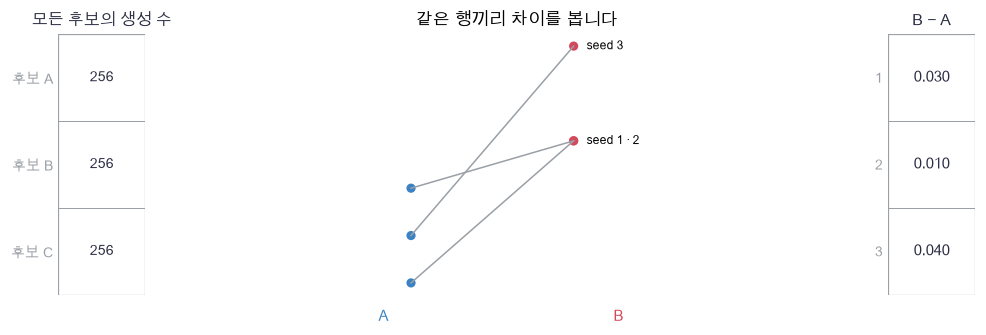

In [38]:
plot_paired_protocol(paired_demo_budgets, ["후보 A", "후보 B", "후보 C"], paired_demo_seeds, paired_demo_a, paired_demo_b, paired_demo_difference)

🔍 **확인** · 예시 표의 생성 수는 같고, 같은 seed 행의 두 점을 연결했습니다. 차이는 .03·.01·.04로 실행마다 다릅니다. 이 그림은 평균 계산을 설명하는 손계산이며 아래 실제 결과와 구분합니다.

실제 비교에서는 원본 좌표에서 NLL을 계산하고, train에서 고정한 $\mu,s,h$로 MMD를 계산합니다. 오른쪽 영역 비율의 기준은 이 대칭 정답 분포의 .5입니다. 한 성분의 NLL이 나빠도 값을 버리지 않고 그대로 남깁니다.

In [39]:
# 쓰는 것: TRUE_MODEL (2절) · sample_mixture (2절)
def make_candidates(train, learned):
    """정답·학습 모형·실패 진단의 목록. train: (N,1), learned: 학습 GMM → (이름, 종류, 밀도 모형) 목록."""
    gaussian = {"weights": np.array([1.]), "means": np.array([train.mean()]), "variances": np.array([train.var()])}
    mode = int(learned["weights"].argmax())
    collapsed = {"weights": np.array([1.]), "means": learned["means"][[mode]], "variances": learned["variances"][[mode]]}
    return [("oracle", "density", TRUE_MODEL), ("EM-GMM", "density", learned),
            ("단일 Gaussian", "density", gaussian), ("한 성분만", "density", collapsed), ("train 재추출", "memory", None)]


def draw_candidate(kind, model, train, count, rng):
    """후보에서 정확히 count개 생성. memory는 train의 행을 복원추출하고, density는 혼합 모형에서 생성합니다."""
    if kind == "memory":
        return train[rng.integers(0, len(train), size=count)].copy()
    return sample_mixture(model, count, rng)

In [40]:
# 쓰는 것: TRUE_MODEL (2절) · heldout_nll (2절) · mixture_logpdf (2절) · mmd2_v (3절) · region_mass (2절) · transform (1절)
def evaluate_generated(generated, own_model, train, test, mean, scale, kernel_bandwidth, coverage_threshold):
    """같은 표본 묶음에서 별개의 평가 질문을 계산합니다. generated: (M,1), own_model은 연속 밀도 없으면 None."""
    masses = region_mass(generated)
    own_nll = None if own_model is None else heldout_nll(test, own_model)
    oracle_sample_nll = float(-mixture_logpdf(generated, TRUE_MODEL).mean())
    scaled_generated = transform(generated, mean, scale)
    scaled_reference = transform(test, mean, scale)
    return {
        "own_test_nll": own_nll,
        "oracle_sample_nll": oracle_sample_nll,
        "mmd2_v": mmd2_v(scaled_reference, scaled_generated, kernel_bandwidth),
        "right_mass": float(masses[1]),
        "region_coverage": int(np.sum(masses >= coverage_threshold)),
        "train_exact_copy": float(np.isin(generated[:, 0], train[:, 0]).mean()),
        "unique_fraction": len(np.unique(generated, axis=0)) / len(generated),
    }

📎 **독립 난수열과 비용 범위** · 모델 초기화는 각 `seed`, 후보별 생성은 `seed + 10000*(후보번호+1)`을 사용해 분리합니다. 후보 번호와 seed 목록은 고정되어 있습니다. `np.isin`은 생성한 1차원 값이 학습 표본 중 하나와 **정확히 같은지** 검사합니다. 근사한 그림의 암기를 판정하는 기준으로 일반화하지 않습니다.

In [41]:
# 쓰는 것: PLAN (1절) · bandwidth (3절) · fit_gmm (2절) · test_X (2절) · train_X (2절) · train_mean (3절) · train_scale (3절)
comparison_rows, fit_records = [], []
for repeat_seed in PLAN["repeat_seeds"]:
    fit_start = time.perf_counter()
    learned, history, initial = fit_gmm(train_X, np.random.default_rng(repeat_seed), PLAN["em_steps"], PLAN["variance_floor"])
    fit_records.append({"seed": repeat_seed, "gmm_fit_seconds": time.perf_counter()-fit_start})
    for candidate_index, (name, kind, density_model) in enumerate(make_candidates(train_X, learned)):
        draw_seed = repeat_seed + 10000*(candidate_index+1)
        draw_rng = np.random.default_rng(draw_seed)
        sample_start = time.perf_counter()
        generated = draw_candidate(kind, density_model, train_X, PLAN["generated_count"], draw_rng)
        sample_seconds = time.perf_counter() - sample_start
        assert generated.shape == (PLAN["generated_count"], 1), "모든 후보는 정한 수만큼 생성해야 합니다"
        metrics = evaluate_generated(generated, density_model, train_X, test_X, train_mean, train_scale, bandwidth, PLAN["coverage_threshold"])
        comparison_rows.append({"seed": repeat_seed, "draw_seed": draw_seed, "name": name, "count": len(generated), "sample_seconds": sample_seconds, **metrics})
print("모든 실행:", len(comparison_rows), "행 · 고정 평가 관측:", len(test_X))
print("GMM 학습 시간(초):", [round(record["gmm_fit_seconds"], 5) for record in fit_records])

모든 실행: 25 행 · 고정 평가 관측: 512
GMM 학습 시간(초): [0.00277, 0.00249, 0.00256, 0.00266, 0.00249]


In [42]:
# 쓰는 것: fitted_model (2절) · train_X (2절)
candidate_names = [entry[0] for entry in make_candidates(train_X, fitted_model)]
summary_keys = ["mmd2_v", "oracle_sample_nll", "train_exact_copy"]
summary_means, summary_stds = [], []
print("후보 | own test NLL | oracle sample NLL | MMD² V 평균±SD | coverage | 정확한 train 복제 | 생성 초")
for name in candidate_names:
    rows = [row for row in comparison_rows if row["name"] == name]
    metrics_array = np.array([[row[key] for key in summary_keys] for row in rows])
    summary_means.append(metrics_array.mean(axis=0))
    summary_stds.append(metrics_array.std(axis=0, ddof=1))
    nll_values = [row["own_test_nll"] for row in rows if row["own_test_nll"] is not None]
    nll_text = f"{np.mean(nll_values):.4f}" if nll_values else "해당 없음"
    coverage_values = [row["region_coverage"] for row in rows]
    time_mean = np.mean([row["sample_seconds"] for row in rows])
    print(f"{name} | {nll_text} | {metrics_array[:, 1].mean():.4f} | {metrics_array[:, 0].mean():.5f} ± {metrics_array[:, 0].std(ddof=1):.5f} | {coverage_values} | {metrics_array[:, 2].mean():.3f} | {time_mean:.6f}")
summary_means, summary_stds = np.array(summary_means), np.array(summary_stds)

후보 | own test NLL | oracle sample NLL | MMD² V 평균±SD | coverage | 정확한 train 복제 | 생성 초
oracle | 1.4517 | 1.4371 | 0.00096 ± 0.00083 | [2, 2, 2, 2, 2] | 0.000 | 0.000025
EM-GMM | 1.4513 | 1.4081 | 0.00090 ± 0.00043 | [2, 2, 2, 2, 2] | 0.000 | 0.000022
단일 Gaussian | 2.1322 | 4.4028 | 0.02721 ± 0.00555 | [2, 2, 2, 2, 2] | 0.000 | 0.000020
한 성분만 | 16.4988 | 1.4145 | 0.37724 ± 0.00468 | [1, 1, 1, 1, 1] | 0.000 | 0.000017
train 재추출 | 해당 없음 | 1.4351 | 0.00150 ± 0.00200 | [2, 2, 2, 2, 2] | 1.000 | 0.000015


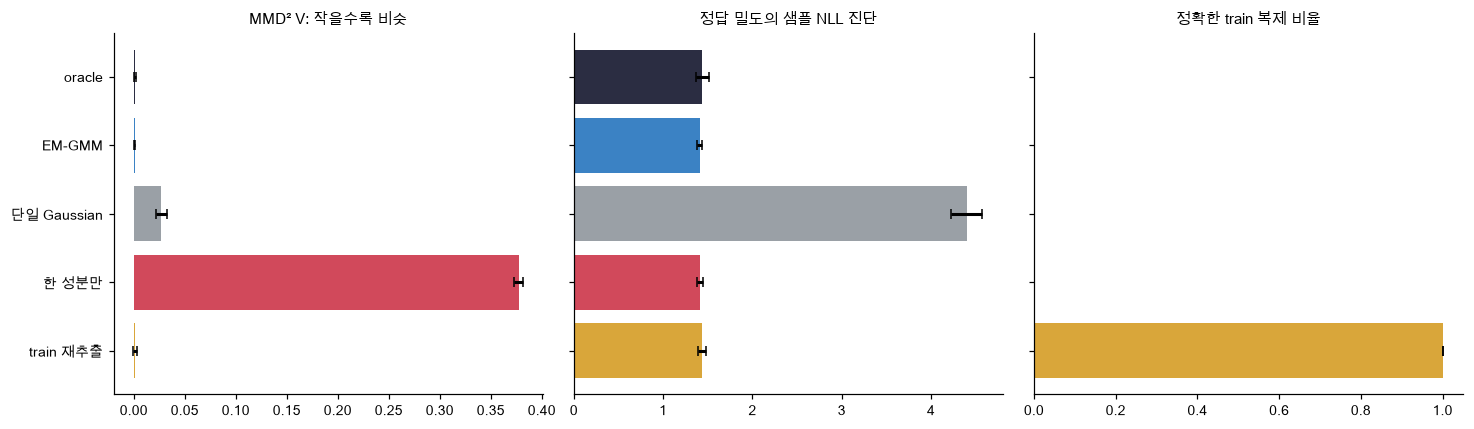

In [43]:
plot_comparison_summary(candidate_names, summary_means, summary_stds, ["MMD² V: 작을수록 비슷", "정답 밀도의 샘플 NLL 진단", "정확한 train 복제 비율"])

🔍 **확인** · EM-GMM은 학습한 두 봉우리의 밀도로 새로운 test 관측을 설명합니다. 한 성분만 남긴 진단은 다른 봉우리 관측의 own NLL에 큰 벌점을 받습니다. 반면 정답 밀도로 잰 생성샘플 NLL은 그 누락을 충분히 드러내지 못할 수 있습니다.

train 재추출은 MMD나 영역 질량에서 괜찮아 보일 수 있지만 정확한 학습 표본 복제 비율은 1입니다. 그 후보의 연속 NLL은 0으로 채우지 않고 "해당 없음"으로 두었습니다. 표본 수를 늘려도 복제 문제를 스스로 해결하지 않습니다. 이 결과로 GAN·VAE·diffusion 중 어느 것이 우수하다고 결론내릴 수 없습니다. 그 모델의 실제 학습·생성 출력을 같은 평가 계약에 연결해야 그런 비교를 시작할 수 있습니다.

In [44]:
# 쓰는 것: PLAN (1절) · bandwidth (3절) · train_mean (3절) · train_scale (3절)
assert len(comparison_rows) == 5*len(PLAN["repeat_seeds"]), "다섯 후보의 모든 seed 실행을 기록해야 합니다"
assert all(row["count"] == PLAN["generated_count"] for row in comparison_rows), "생성 수의 분모가 모두 같아야 합니다"
assert all(row["mmd2_v"] >= -1e-12 for row in comparison_rows), "V통계 제곱은 반올림 수준 밖에서 음수가 아니어야 합니다"
memory_rows = [row for row in comparison_rows if row["name"] == "train 재추출"]
assert all(row["own_test_nll"] is None for row in memory_rows), "연속 밀도가 없는 후보의 NLL은 비워 두어야 합니다"
np.testing.assert_allclose([row["train_exact_copy"] for row in memory_rows], 1.)  # 검산: train 재추출은 전부 정확한 복제
gmm_mmd = np.array([row["mmd2_v"] for row in comparison_rows if row["name"] == "EM-GMM"])
memory_mmd = np.array([row["mmd2_v"] for row in memory_rows])
paired_mmd_difference = memory_mmd - gmm_mmd
print("재추출 − EM-GMM의 seed별 MMD² 차이:", paired_mmd_difference)
print("차이의 평균 / 표준편차:", paired_mmd_difference.mean(), paired_mmd_difference.std(ddof=1))
experiment_record = {"plan": PLAN.copy(), "standardizer_mean": train_mean.tolist(), "standardizer_scale": train_scale.tolist(), "rbf_bandwidth": bandwidth, "mmd_estimator": "biased squared V, diagonals included", "rows": comparison_rows, "fit_records": fit_records}
print("고정 계획·전체 실행 수·복제 진단 검산 통과 · 결과는 experiment_record에 있습니다.")

재추출 − EM-GMM의 seed별 MMD² 차이: [-0.00056409  0.00379474 -0.00038825 -0.00036668  0.00052548]
차이의 평균 / 표준편차: 0.0006002391801411822 0.0018356285802011037
고정 계획·전체 실행 수·복제 진단 검산 통과 · 결과는 experiment_record에 있습니다.


### ✏️ 연습 5 · 생성점이 아니라 seed 행을 평균내기

`scores:(R,C)`는 실행 R개 × 후보 C개의 점수입니다. 실행 축의 평균과 표본 표준편차를 구하세요. 이 예제에서는 모든 행의 생성 수가 같습니다.

In [45]:
def exercise_seed_summary(scores):
    """연습 5: seed별 평균·표본 표준편차. scores: (R,C), R≥2 → mean, std: (C,)."""
    ### 구현할 내용: axis=0의 평균과 ddof=1인 표준편차
    raise NotImplementedError
    return mean, std

In [46]:
def check_seed_summary(candidate):
    """후보 두 개의 세 실행을 손으로 집계합니다."""
    mean, std = candidate(np.array([[1., 4.], [2., 4.], [3., 4.]]))
    np.testing.assert_allclose(mean, [2., 4.])  # 검산: 후보별 세 실행의 평균
    np.testing.assert_allclose(std, [1., 0.])  # 검산: sqrt((1+0+1)/(3-1)), 같은 값의 변동은 0
    print("seed 집계: 실험 행을 평균낸 값과 일치합니다.")

run_check(check_seed_summary, exercise_seed_summary, hint="mean = scores.mean(axis=0), std = scores.std(axis=0, ddof=1)")

☐ exercise_seed_summary: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: mean = scores.mean(axis=0), std = scores.std(axis=0, ddof=1)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mean = scores.mean(axis=0)
std = scores.std(axis=0, ddof=1)
```

</details>

## ✏️ 6. 직접 채워서 확인합니다

아래 A–D는 관측 평균·커널 분모·최근접 거리·짝지은 실행을 다시 연결합니다. 한 번에 한두 줄만 채운 뒤 작은 손계산과 대조하세요. 각 정답은 바로 아래에서 펼쳐 볼 수 있습니다.

### ✏️ 연습 A · 평가 관측의 log density를 평균 손실로

모델이 평가 관측 각각에 준 `log_density:(N,)`에서 평균 NLL을 구하세요. 샘플의 평균 밀도에 로그를 취하는 계산과 구분합니다.

In [47]:
def exercise_mean_nll(log_density):
    """연습 A: 관측 평균 NLL. log_density: (N,) → nll: 숫자."""
    ### 구현할 내용: 로그 밀도에 음수를 붙여 평균냅니다.
    raise NotImplementedError
    return nll

In [48]:
def check_mean_nll(candidate):
    """log 값 둘의 평균과 균등 복제 시 불변을 확인합니다."""
    logs = np.log(np.array([.25, .5]))
    expected = 1.5*np.log(2.)
    np.testing.assert_allclose(candidate(logs), expected)  # 검산: (log4+log2)/2
    np.testing.assert_allclose(candidate(np.repeat(logs, 3)), expected)  # 검산: 같은 관측을 반복해도 평균은 같음
    np.testing.assert_allclose(candidate(np.array([np.log(2.)])), -np.log(2.))  # 검산: 밀도는 1보다 클 수 있어 NLL도 음수 가능
    print("관측 NLL: 손계산과 일치합니다.")

run_check(check_mean_nll, exercise_mean_nll, hint="nll = -log_density.mean()")

☐ exercise_mean_nll: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: nll = -log_density.mean()


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
nll = -log_density.mean()
```

</details>

### ✏️ 연습 B · 크기가 다른 세 커널 표의 분모

이미 계산한 `KXX:(N,N)`, `KYY:(M,M)`, `KXY:(N,M)`로 biased MMD²를 구하세요. 자기 쌍 대각항도 포함합니다.

In [49]:
def exercise_mmd2_from_kernels(KXX, KYY, KXY):
    """연습 B: 커널 평균 세 개의 V통계. KXX:(N,N), KYY:(M,M), KXY:(N,M) → value."""
    ### 구현할 내용: 자기 표 평균 두 개에서 교차 표 평균의 두 배를 뺍니다.
    raise NotImplementedError
    return value

In [50]:
def check_mmd2_from_kernels(candidate):
    """N=2, M=1인 RBF 손계산과 동일 표를 검사합니다."""
    a = np.exp(-.5)
    KXX = np.array([[1., a], [a, 1.]])
    KYY, KXY = np.ones((1, 1)), np.array([[1.], [a]])
    np.testing.assert_allclose(candidate(KXX, KYY, KXY), (1-a)/2)  # 검산: (.5+.5a)+1-2*(.5+.5a)
    np.testing.assert_allclose(candidate(KXX, KXX, KXX), 0., atol=1e-12)  # 검산: 같은 경험 분포는 0
    print("커널 표의 분모: 크기가 달라도 손계산과 일치합니다.")

run_check(check_mmd2_from_kernels, exercise_mmd2_from_kernels, hint="value = KXX.mean() + KYY.mean() - 2*KXY.mean()")

☐ exercise_mmd2_from_kernels: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: value = KXX.mean() + KYY.mean() - 2*KXY.mean()


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = KXX.mean() + KYY.mean() - 2*KXY.mean()
```

</details>

### ✏️ 연습 C · 최근접 그림의 번호와 화소 RMS

제곱 거리 표 `distances:(N,R)`에서 행마다 가장 가까운 참조 번호를 고르고, 그 값을 화소 수 D로 나눈 뒤 제곱근을 취하세요. `distances[np.arange(N), index]`는 각 행에서 고른 칸을 읽습니다.

In [51]:
def exercise_nearest_from_distances(distances, dimension):
    """연습 C: 최근접 번호·RMS. distances: (N,R) 거리², dimension: D → index, rms: (N,)."""
    ### 구현할 내용: 행별 argmin으로 index, 선택한 거리² / D의 제곱근으로 rms
    raise NotImplementedError
    return index, rms

In [52]:
def check_nearest_from_distances(candidate):
    """참조 크기와 입력 크기가 다른 거리 표를 손으로 읽습니다."""
    index, rms = candidate(np.array([[8., 0., 2.], [18., 8., 32.]]), 2)
    np.testing.assert_array_equal(index, [1, 1])  # 검산: 두 행 모두 1번 참조가 최소
    np.testing.assert_allclose(rms, [0., 2.])  # 검산: sqrt(0/2), sqrt(8/2)
    print("최근접 RMS: 손계산과 일치합니다.")

run_check(check_nearest_from_distances, exercise_nearest_from_distances, hint="index = distances.argmin(axis=1), rms = np.sqrt(distances[np.arange(len(distances)), index] / dimension)")

☐ exercise_nearest_from_distances: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: index = distances.argmin(axis=1), rms = np.sqrt(distances[np.arange(len(distances)), index] / dimension)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
index = distances.argmin(axis=1)
rms = np.sqrt(distances[np.arange(len(distances)), index] / dimension)
```

</details>

### ✏️ 연습 D · 같은 실행끼리 차이를 낸 뒤 변동 읽기

`scores_a, scores_b:(R,)`는 같은 순서의 seed 점수입니다. 먼저 B−A의 차이를 구하고 그 차이의 평균·표본 표준편차를 반환하세요. 각각의 표준편차를 더하는 계산과 다릅니다.

In [53]:
def exercise_paired_difference(scores_a, scores_b):
    """연습 D: 짝지은 차이 집계. scores_a, scores_b: (R,) → mean, std: 숫자 둘."""
    assert scores_a.shape == scores_b.shape, "같은 실행끼리 대응해야 합니다"
    ### 구현할 내용: difference = B-A, summary = 차이의 평균과 ddof=1 표준편차
    raise NotImplementedError
    return summary

In [54]:
def check_paired_difference(candidate):
    """각 후보는 흔들리지만 차이는 고정된 경우와 다른 차이들을 검사합니다."""
    mean, std = candidate(np.array([1., 5., 9.]), np.array([3., 7., 11.]))
    np.testing.assert_allclose([mean, std], [2., 0.])  # 검산: 각 실행의 차이는 전부 2
    mean, std = candidate(np.array([1., 1., 1.]), np.array([0., 1., 2.]))
    np.testing.assert_allclose([mean, std], [0., 1.])  # 검산: 차이 -1·0·1의 평균과 표본 표준편차
    print("짝지은 차이: 손계산과 일치합니다.")

run_check(check_paired_difference, exercise_paired_difference, hint="difference = scores_b - scores_a, summary = (difference.mean(), difference.std(ddof=1))")

☐ exercise_paired_difference: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: difference = scores_b - scores_a, summary = (difference.mean(), difference.std(ddof=1))


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
difference = scores_b - scores_a
summary = (difference.mean(), difference.std(ddof=1))
```

</details>

### ✏️ 준비도 질문 · 네 가지를 따로 확인합니다

- **설명:** held-out NLL·복원 오차·생성 표본 진단이 각각 무엇을 묻는지, train 재추출의 연속 NLL을 왜 비워 두는지 설명할 수 있나요? → 1·2·5절
- **수식:** MMD²의 세 행렬 shape와 $N^2,M^2,NM$ 분모, 대각항 포함 여부, 특징 공분산의 분모 $N$을 쓸 수 있나요? → 3·4절
- **구현:** 커널 함수·영역 질량·최근접 RMS와 고유 그림 비율을 본문을 가리고 다시 작성할 수 있나요? → 2–4절, 연습 A–C
- **변형 검산:** 생성 수·대역폭·seed를 하나씩 바꾸되 설정 선택과 최종 평가를 구분하고, 달라진 숫자의 원인과 실험 단위를 기록할 수 있나요? 같은 그림을 두 배 복제했을 때 변하지 않을 지표와 변하는 개수를 먼저 예상할 수 있나요? → 3–5절, 연습 D

### 📎 다음 실험으로 연결하기

25번의 복원은 입력별 복원 쌍으로 따로 보고하고, 28·32–35b의 생성 샘플을 비교할 때에는 같은 원본 데이터·PCA 기저·표본 수·평가 특징을 고정합니다. 정답 밀도를 모르는 실제 이미지에서는 이 노트북의 oracle sample NLL을 만들 수 없습니다. 학습 과정·파라미터·실제 생성 결과를 연결한 뒤에도 여러 지표와 원본 그림을 함께 읽습니다.